In [42]:
import re
import os
from tqdm import tqdm
from collections import defaultdict, Counter

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pydub import AudioSegment
import opensmile

from transformers import AutoTokenizer, AutoModel
from transformers import BertForMaskedLM, BertTokenizer, Trainer, TrainingArguments, DataCollatorForLanguageModeling
from transformers import BertModel
from sklearn.model_selection import train_test_split, cross_val_score
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from focal_loss.focal_loss import FocalLoss
from torch.optim.lr_scheduler import ReduceLROnPlateau, LinearLR
from torch.utils.data import Dataset, DataLoader, Subset
from datasets import Dataset as ds
from sklearn.preprocessing import StandardScaler, RobustScaler, PowerTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import compute_class_weight
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

import shap
from enum import Enum
import umap.umap_ as umap
from imblearn.over_sampling import SMOTE

# NOTE: Here you can choose some config for the embedder.
# 1. Choose model itself (NOTE 2: bge-base-en-v1.5 has shown the best result on Pitt corpus)
# 2. You can choose whether to use max pooling or average pooling in the final layer of embedder
# 3. And you can set the FINE_TUNE flag to True if you want to perform fine tuning of the embedder model (I advise to avoid it)

# NOTE 3: Please, be aware that the embedding of the transcript itself happens inside parse_pitt.py
# Hence, the values below define which type of embedded data to use. In addition, it's advised to use the same embedder 
# in generating the embeddings and training on these embeddings. Taking this into account MODEL_TYPE defines which embedded data 
# to use and which model will be trained on that data

# set type of tokenizer
model_types = ['bert-base-uncased', 'bert-large-uncased', 'ClinicalBERT', 
               'deberta-v3-base', 'roberta-base', 'roberta-large',
               'bge-base-en-v1.5', 'bge-m3'] # m3 is multi-lingual
MODEL_TYPE = model_types[6]
MAX_POOLING = False
FINE_TUNE = False

# Load data

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [5]:
if MAX_POOLING:
    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_MAXP_{MODEL_TYPE}.pkl')
else:
    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_{MODEL_TYPE}.pkl')

In [6]:
df['dementia'].unique()

array(['PossibleAD', 'ProbableAD', 'Memory', 'Vascular', 'MCI', 'Other',
       'Probable', 'Control'], dtype=object)

In [7]:
df

,ID,age,sex,dementia,text,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
0,476-0_cookie,64,female,PossibleAD,clearsthroat hm the woman of the house is dryi...,"[[0.2328364, -0.013145677, 0.30244806, -0.5082...",32.367973,0.169069,28.859549,32.672092,...,0.014956,-0.010772,0.069282,4.552497,3.578753,0.414964,0.119592,0.077508,0.064468,-29.202118
1,183-1_cookie,64,male,ProbableAD,the boy's uh fallin off the stool the the girl...,"[[-0.03674131, 0.12786853, 0.65631753, -0.5119...",25.893515,0.083554,25.068998,26.007025,...,0.019386,-0.003246,0.022419,2.437523,1.581530,0.449667,0.280772,0.284074,0.188013,-31.610138
2,216-0_cookie,72,female,ProbableAD,well there's a kid in a cookie jar there's a g...,"[[0.027450543, 0.26633045, 0.22579488, -0.3187...",30.133780,0.158424,26.081902,31.247602,...,0.036977,-0.013100,0.038447,3.465397,2.478610,0.336407,0.197328,0.126481,0.055212,-37.809464
3,173-1_cookie,71,female,ProbableAD,let's see what's this this well the k lu and t...,"[[0.2747639, 0.14876355, -0.08306462, -0.27240...",29.214741,0.193511,25.452457,28.852304,...,0.038325,-0.020275,0.022480,3.307396,2.552122,0.367143,0.228349,0.163214,0.070129,-46.272060
4,381-0_cookie,75,female,ProbableAD,well the kids are swipin the cookies mom's doi...,"[[-0.12545331, 0.04245159, 0.5988007, 0.156986...",27.629732,0.074770,26.195204,28.142347,...,0.037889,-0.009598,0.008773,3.657219,2.840905,0.122197,0.068713,0.360424,0.285403,-53.288258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1208,128-1_cookie,71,female,Control,oh I remember this one okay the mom's doing th...,"[[-0.76480836, 0.071624234, -0.10603161, -0.76...",30.967085,0.103636,28.283186,30.838778,...,0.054463,-0.014791,0.021959,3.372949,2.116813,0.310652,0.159613,0.214994,0.122742,-45.492466
1209,142-3_cookie,61,female,Control,mhm well the water's running over on the floor...,"[[-0.18051411, 0.082194194, 0.15349738, -0.499...",33.519424,0.088880,32.100095,33.175519,...,0.056380,-0.012752,0.024856,4.028542,1.806884,0.417500,0.195181,0.095458,0.067621,-29.882867
1210,332-0_fluency,50,male,Control,dog cow cat horse sheep mule donkey deer antel...,"[[0.41160834, 0.09187404, -0.34637004, 1.04813...",26.910131,0.028706,26.678370,27.039707,...,-0.001642,-0.000825,0.011415,1.168898,0.703156,0.265128,0.025641,1.202970,0.899072,-54.753613
1211,332-0_recall,50,male,Control,eorge and his granddaughter went to visit ( ) ...,"[[-0.29490897, -0.7212136, 0.6587217, -0.06960...",25.061729,0.053765,24.179365,24.968309,...,0.002817,-0.002691,0.013942,3.129667,1.758500,0.162454,0.099134,0.416941,0.612056,-54.896027


In [8]:
df['embeddings'][0].shape

(1, 768)

In [9]:
def encode_df(df):
    SIMPLE = True

    sex_mapping = {'female': 0,
                   'male': 1}
    dementia_mapping = {'Control' : 0,
                        'PossibleAD' : 1,
                        'ProbableAD' : 1,
                        'Probable' : 1,
                        'Memory' : 2,
                        'Vascular' : 3,
                        'MCI' : 4,
                        'Other' : 5}

    simple_dementia_mapping = {'Control' : 0,
                        'PossibleAD' : 1,
                        'ProbableAD' : 1,
                        'Probable' : 1,
                        'Memory' : 1,
                        'Vascular' : 1,
                        'MCI' : 1,
                        'Other' : 1}
    df['sex'] = df['sex'].map(sex_mapping)

    # I suppose we can keep simple mapping, cuz 'PossibleAD' and 'ProbableAD' are the most common (like 80% of the data)
    if SIMPLE:
        df['dementia'] = df['dementia'].map(simple_dementia_mapping)
    else:
        df['dementia'] = df['dementia'].map(dementia_mapping)
    return df
df = encode_df(df)

In [10]:
# NOTE: Shows amount of unique IDs  in different tasks (NOTE 2: ID might indicate a second recording of the same person, e.g. 123_0 and 123_1 are two different audios of the same person).
# i.e. we chose to train on cookie only, cuz of this
print(f"cookie stats\n{df[df['ID'].str.contains(r'cookie$', regex=True)].groupby('dementia').size()}\n")
print(f"recall stats\n{df[df['ID'].str.contains(r'recall$', regex=True)].groupby('dementia').size()}\n")
print(f"fluency stats\n{df[df['ID'].str.contains(r'fluency$', regex=True)].groupby('dementia').size()}\n")
print(f"sentence stats\n{df[df['ID'].str.contains(r'sentence$', regex=True)].groupby('dementia').size()}\n")

cookie stats
dementia
0    243
1    306
dtype: int64

recall stats
dementia
0      1
1    238
dtype: int64

fluency stats
dementia
0      1
1    210
dtype: int64

sentence stats
dementia
0      1
1    213
dtype: int64



In [11]:
# NOTE: Here I discover that we might leak data if we pass two different recordings of the same person to train and test datasets
# solution - merge the audio features and embeddings by ID. That is, 123_0 and 123_1 become just 123 and all the data is a simple mean of 123_0 and 123_1
# discussion - might be a wrong work around (cuz there's like a few years between each recording in most cases, so the speech pattern might have changed),
# however both embeddings and audio features capture semantic meaning of speech, so in that regard we don't really care if there's been some time between the 
# recordings, cuz the person is the same. Feel free to debate.

'''
PROBLEM. The non cookie data has only one control, which is bad in and of itself, so I will only use cookie data.
HOWEVER! Almost each patient has like from 2 to 5 samples (e.g. 123_0, 123_1 and so on), so when we split the data recordings 
of the same patient might appear in test and train at the same time. Now I just merge their data.
'''
df = df[df['ID'].str.contains(r'cookie$', regex=True)]
df['ID'] = df['ID'].str.extract(r'^(\d{3})')
df = df.drop(columns=['text'])
df = df.groupby('ID', as_index=False).mean()
df = df[df['dementia'].isin([0, 1])] 

/tmp/ipykernel_10063/3710434885.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ID'] = df['ID'].str.extract(r'^(\d{3})')


In [12]:
df

,ID,age,sex,dementia,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
0,001,58.0,1.0,1.0,"[[-0.11217372119426727, 0.14132604002952576, 0...",24.007486,0.249831,20.184769,22.278211,26.457061,...,0.029529,-0.009069,0.101949,3.104930,2.371126,0.477314,0.311443,0.106744,0.102437,-32.413410
1,002,59.5,0.0,0.0,"[[-0.07445148378610611, 0.29084306955337524, 0...",28.993107,0.122108,26.548655,28.391636,31.503487,...,0.044682,-0.003132,0.019453,2.879837,1.675057,0.245219,0.146539,0.571197,0.244049,-50.502188
2,003,56.0,1.0,1.0,"[[0.18623605370521545, 0.44952622056007385, 0....",23.200605,0.201415,20.125063,22.841703,25.770544,...,0.042396,-0.015316,0.182064,3.170367,1.757709,0.770903,0.539168,0.088298,0.105145,-29.459497
3,005,54.0,1.0,1.0,"[[-0.32142481207847595, -0.3126828968524933, 0...",23.708063,0.113381,20.987274,22.767417,26.742311,...,0.043387,-0.007752,0.040804,3.725629,1.614170,0.659851,0.114319,0.154628,0.032852,-39.530314
4,006,73.0,1.0,0.0,"[[-0.04464384913444519, 0.3454661766688029, 0....",26.026248,0.208428,23.685170,25.224073,27.665803,...,0.047626,-0.007929,0.091308,3.464252,1.937064,0.488675,0.295809,0.154428,0.145268,-29.243555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286,705,71.0,0.0,1.0,"[[-0.6432255506515503, -0.11714281886816025, -...",28.509546,0.235985,23.385406,29.888838,32.735504,...,0.021433,-0.003191,0.225758,3.565626,2.612877,0.321065,0.199789,0.083958,0.072360,-18.652487
287,707,74.0,0.0,1.0,"[[-0.04445631057024002, 0.4192982017993927, 0....",28.969143,0.161608,26.807579,28.887688,31.861370,...,0.032612,-0.004763,0.202274,4.374685,2.322151,0.576619,0.253957,0.048577,0.020491,-21.267094
288,709,75.0,0.0,0.0,"[[-0.24163810908794403, 0.34041866660118103, 0...",29.200554,0.141155,26.425854,29.351512,32.293810,...,0.051244,-0.007034,0.123923,3.133558,2.192243,0.219631,0.140634,0.333764,0.217503,-40.202064
289,711,77.0,1.0,1.0,"[[0.09661481529474258, 0.4294782876968384, 0.4...",24.532228,0.231943,21.884371,23.732145,25.483189,...,0.019180,-0.005968,0.461831,3.589783,2.220657,0.450595,0.346124,0.056059,0.043653,-18.531303


In [13]:
df.groupby('dementia').size()

dementia
0.0     98
1.0    192
dtype: int64

# Data prep

In [14]:
# NOTE: Audio data had to be scaled using StandardScaler, due to significantly different ranges in some of the audio features (i.e. some range from 0 to 1, and some range from 1000 to 5000)
class PittDataset(Dataset):
    def __init__(self, embeddings, audio_features, age, sex, labels, audio_scaler=None, age_scaler=None, scale_audio=True):
        self.embeddings = embeddings
        self.audio_features = audio_features
        self.age = age.reshape(-1, 1)  # .reshape(-1,1) to keep it as a single feature
        self.sex = sex.reshape(-1, 1)
        self.labels = labels
        
        # Separate scalers for different features
        self.age_scaler = age_scaler or StandardScaler()

        if scale_audio:
            self.audio_scaler = audio_scaler or StandardScaler()
            
            if audio_scaler is None:
                self.audio_features = self.audio_scaler.fit_transform(self.audio_features)
            else:
                self.audio_features = self.audio_scaler.transform(self.audio_features)
            
        if age_scaler is None:
            self.age = self.age_scaler.fit_transform(self.age)
        else:
            self.age = self.age_scaler.transform(self.age)


    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'embeddings': torch.tensor(self.embeddings[idx], dtype=torch.float32),
            'audio_features': torch.tensor(self.audio_features[idx], dtype=torch.float32),
            'age': torch.tensor(self.age[idx], dtype=torch.float32),
            'sex': torch.tensor(self.sex[idx], dtype=torch.float32),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)  # Changed to long for CE loss
        }

In [15]:
def make_datasets(df): 
    embeddings = np.stack(df['embeddings'].values)
    if 'text' in df.columns:
        audio_features = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex', 'text']).values
        text = df['text'].values
    else:
        audio_features = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values
    age = df['age'].values
    sex = df['sex'].values
    labels = df['dementia'].values

    '''
     there's some magic with embeddings, df['embeddings'].values returns an array with arrays inside with the shape of (n_samples,)
     it's like a list with these arrays, but we need to glue them together to get their real shape, that's why we use np.stack()
     however, it returns the needed array with the shape of (n_samples, 1, 768), and that's why we squeeze it
     as a result we get the shape of (n_samples, 768)
    '''
    if len(embeddings.shape) > 2:
        embeddings = np.squeeze(embeddings, axis=1)

    X_emb_train, X_emb_test, X_audio_train, X_audio_test, X_age_train, X_age_test, X_sex_train, X_sex_test, y_train, y_test = train_test_split(
        embeddings, 
        audio_features, 
        age, 
        sex,
        labels, test_size=0.2, stratify=df['dementia'])

    train_dataset = PittDataset(X_emb_train, X_audio_train, X_age_train, X_sex_train, y_train)
    test_dataset = PittDataset(X_emb_test, X_audio_test, X_age_test, X_sex_test, y_test, train_dataset.audio_scaler, train_dataset.age_scaler)
    print(f'Test: {Counter(y_test)}')
    print(f'Train: {Counter(y_train)}')
    
    return train_dataset, test_dataset, y_train, embeddings, audio_features, age, sex, labels


### Fine tune BERT on the other tasks (UNUSED)
Please, refrain from using this snippet, it's been done for testing purposes

In [16]:
if FINE_TUNE:
    bert_model = BertForMaskedLM.from_pretrained('bert-base-uncased')
    tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
    
    tuning_df = pd.read_pickle('/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_bert-base-uncased.pkl')
    tuning_df = tuning_df[~tuning_df['ID'].str.contains(r'cookie$', regex=True)]
    tuning_df = tuning_df[~tuning_df['dementia'].isin(['Control'])]  # fix: assign back to df
    
    list_of_dementia_texts = tuning_df['text'].tolist()
    
    dataset = ds.from_dict({"text": list_of_dementia_texts})
    
    def tokenize_function(examples):
        return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)
    
    tokenized_dataset = dataset.map(tokenize_function, batched=True, remove_columns=["text"])
    
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=True, mlm_probability=0.15)
    
    training_args = TrainingArguments(
        output_dir='/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased-mlm',
        per_device_train_batch_size=8,
        num_train_epochs=3,
        save_steps=10_000,
        save_total_limit=2,
        prediction_loss_only=True,
        logging_steps=500,
    )
    
    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=tokenized_dataset,
        data_collator=data_collator,
    )
    
    trainer.train()

    bert_model.save_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned')
    tokenizer.save_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned')

    df = pd.read_pickle(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_data_bert-base-uncased.pkl')
    df['embeddings'] = np.nan
    fine_tuned_bert = BertModel.from_pretrained(f'/home/gabs/Documents/lab-NN/cognitive_impairments/data/tokenizers/bert-base-uncased_finetuned').to(device)
    def get_bert_embeddings(texts, model):
        inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=512).to(device)
        with torch.no_grad():
            outputs = model(**inputs.to(device))
        return outputs.last_hidden_state.mean(dim=1).cpu().numpy() 
    
    tqdm.pandas(desc="Generating embeddings")
    df['embeddings'] = df['text'].progress_apply(get_bert_embeddings, model = fine_tuned_bert)
    df = encode_df(df)
    df = df[df['ID'].str.contains(r'cookie$', regex=True)]
    df['ID'] = df['ID'].str.extract(r'^(\d{3})')
    df = df.drop(columns=['text'])
    df = df.groupby('ID', as_index=False).mean()
    df = df[df['dementia'].isin([0, 1])] 

### Get datasets

In [17]:
train_dataset, test_dataset, y_train, embeddings, audio_features, age, sex, labels = make_datasets(df)
print("Scaled audio features stats:")
print(f"Min: {train_dataset.audio_features.min()}, Max: {train_dataset.audio_features.max()}")
print(f"Mean: {train_dataset.audio_features.mean()}, Std: {train_dataset.audio_features.std()}")
train_dataset.audio_features.shape

Test: Counter({np.float64(1.0): 38, np.float64(0.0): 20})
Train: Counter({np.float64(1.0): 154, np.float64(0.0): 78})
Scaled audio features stats:
Min: -15.117639246118285, Max: 13.641095051530932
Mean: 3.1322906650866487e-18, Std: 1.0


(232, 88)

# Train Model


In [ ]:
# NOTE: This is the arch of the model. The model itself is multibranch, that is, it has 3 parallel networks that pool theit result into
# the last classifier network which in turn predicts the class of a record.
# First branch - works with embedded transcript, 9 layers, for stability purpouses, it uses GELU instead of ReLU; 
# Initial embedding demintionality reduction is quite high as it goes from 768 (or higher, depending on the embedder) to 256. In addition the there are relatively high dropout rates.
# All this ensures the stability of the model as the embedded transcript data is fairly nosy, and might basically "clog up" the reasoning
# Second branch - worsk with OpenSMILE Audio features, 8 layers, for stability purpouses, it uses GELU instead of ReLU;
# As we chose to use only essential features (eGeMAPS set of 75 feats), this branch doesn't require such a high level of dementionality reduction.
# Third branch - works with demographic data (age and sex), 6 layers, GELU used once again;
# In this case we had to bum up the dementionality from 2 to 64 to give the demographic data some more weight
# Final branch - Classifier itself, 5 layers, GELU once again; pools together the data of all the other branches and makes a decision on the class of data

class PittNet(nn.Module):
    def __init__(self, emb_dim, audio_dim, num_classes, debug=False):
        super().__init__()

        self.embeddings_branch = nn.Sequential(
            nn.Linear(emb_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(128, 64)
        )

        self.audio_branch = nn.Sequential(
            nn.Linear(audio_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.4), 
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.GELU(),
            nn.Dropout(0.2),
        )

        self.demographics_branch = nn.Sequential(
            nn.Linear(2, 32),  # age + sex (label encoded)
            nn.GELU(),
            nn.Dropout(0.05),
            nn.Linear(32, 32),
            nn.GELU(),       
            nn.Linear(32, 64) 
        )

        self.classifier = nn.Sequential(
            nn.Linear(64+32+64, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
        )

        self.debug = debug
        self.emb_mag = []
        self.audio_mag = []
        self.demo_mag = []
        self.temperature = nn.Parameter(torch.ones(1))
    
    
    def forward(self, embeddings, audio_features, age, sex):
        demo = torch.cat([age, sex], dim=1)
        emb_out = self.embeddings_branch(embeddings)
        audio_out = self.audio_branch(audio_features)
        demo_out = self.demographics_branch(demo)

        combined = torch.cat([emb_out, audio_out, demo_out], dim=1)

        if self.debug and torch.is_grad_enabled():  # Only log during training
            self.emb_mag.append((emb_out.norm(2, dim=1).mean().cpu().detach().numpy(), emb_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)
            self.audio_mag.append((audio_out.norm(2, dim=1).mean().cpu().detach().numpy(), audio_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)
            self.demo_mag.append((demo_out.norm(2, dim=1).mean().cpu().detach().numpy(), demo_out.norm(2, dim=1).std().cpu().detach().numpy())) # (mean mag per branch, std)

        return self.classifier(combined) / self.temperature, {'emb': self.emb_mag, 'audio': self.audio_mag , 'demo': self.demo_mag}



In [64]:
def run_epochs(epochs, model, train_loader, test_loader, optimizer, loss_fn, patience=5, debug=False, plots=True):
    train_loss_his, train_acc_his = [], []
    test_loss_his, test_acc_his = [], []

    patience = patience
    best_loss = float('inf')
    best_auc = 0
    no_improve = 0


    for epoch in range(epochs):

        model.train()
        train_loss, train_acc = 0, 0

        all_preds = []
        all_labels = []

        for batch in train_loader:
            emb = batch['embeddings'].to(device)
            audio = batch['audio_features'].to(device)
            age = batch['age'].to(device)
            sex = batch['sex'].to(device)

            labels = batch['label'].to(device)

            logits, debug_data = model(emb, audio, age, sex)
            pred = F.softmax(logits, dim=1)

            loss = loss_fn(logits, labels)
            train_loss += loss.item()
            train_acc += accuracy_score(labels.cpu(), pred.argmax(dim=1).cpu())

            

            all_preds.extend(pred.argmax(dim=1).cpu())
            all_labels.extend(labels.cpu())

            optimizer.zero_grad()

            loss.backward()

            #torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

        train_loss /= len(train_loader)
        train_acc /= len(train_loader)
        train_loss_his.append(train_loss)
        train_acc_his.append(train_acc)
        train_f1 = f1_score(all_labels, all_preds)
        train_auc = roc_auc_score(all_labels, all_preds)
        train_recall = recall_score(all_labels, all_preds)
        train_precision = precision_score(all_labels, all_preds)
        train_con_mat = confusion_matrix(all_labels, all_preds)
        #train_report = classification_report(all_labels, all_preds)


        with torch.inference_mode():
            model.eval()
            test_loss, test_acc = 0, 0

            all_test_preds = []
            all_test_labels = []

            for batch in test_loader:
                emb = batch['embeddings'].to(device)
                audio = batch['audio_features'].to(device)
                age = batch['age'].to(device)
                sex = batch['sex'].to(device)

                test_labels = batch['label'].to(device)

                test_logits, _ = model(emb, audio, age, sex)
                test_pred = F.softmax(test_logits, dim=1)

                loss = loss_fn(test_logits, test_labels)

                test_loss += loss.item()
                test_acc += accuracy_score(test_labels.cpu(), test_pred.argmax(dim=1).cpu())

                all_test_preds.extend(test_pred.argmax(dim=1).cpu())
                all_test_labels.extend(test_labels.cpu())

            test_loss /= len(test_loader)
            test_acc /= len(test_loader)
            test_loss_his.append(test_loss)
            test_acc_his.append(test_acc)
            test_f1 = f1_score(all_test_labels, all_test_preds)
            test_auc = roc_auc_score(all_test_labels, all_test_preds)
            test_recall = recall_score(all_test_labels, all_test_preds)
            test_precision = precision_score(all_test_labels, all_test_preds)
            test_con_mat = confusion_matrix(all_test_labels, all_test_preds)
            #test_report = classification_report(all_test_labels, all_test_preds)

        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}:{epochs-1}------------------------") # 0 based counting, don't worry
            print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f} | Train F1: {train_f1:.2f} | Train AUC: {train_auc:.2f} | Train Recall: {train_recall:.2f} | Train Precision: {train_precision:.2f}")
            print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
            print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
            print(f"Train confusion matrix: \n{train_con_mat}")
            print(f"Test confusion matrix: \n{test_con_mat}\n")
            #print(f'Train: \n{train_report}')
            #print(f'Test: \n{test_report}\n')

        if test_loss < best_loss and test_auc > best_auc:
            best_loss = test_loss
            no_improve = 0
            final_metrics = {
                'train_acc': train_acc,
                'test_acc': test_acc,
                'train_f1': train_f1,
                'test_f1': test_f1,
                'train_auc': train_auc,
                'test_auc': test_auc,
                'train_recall': train_recall,
                'test_recall': test_recall,
                'train_precision': train_precision,
                'test_precision': test_precision,
                'test_confusion_matrix': test_con_mat,
            }
        else:
            no_improve += 1

        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch}")
            print(f"Epoch {epoch}:{epochs-1}------------------------") # 0 based counting, don't worry
            print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f} | Train F1: {train_f1:.2f} | Train AUC: {train_auc:.2f} | Train Recall: {train_recall:.2f} | Train Precision: {train_precision:.2f}")
            print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
            print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
            print(f"Train confusion matrix: \n{train_con_mat}")
            print(f"Test confusion matrix: \n{test_con_mat}\n")
            break
    
    if plots:
        fig, ax = plt.subplots()
        ax.plot(test_loss_his, label='Test loss')
        ax.plot(train_loss_his, label='Train loss')
        plt.ylim(0, 1) 
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
    
        fig, ax = plt.subplots()
        ax.plot(test_acc_his, label='Test accuracy')
        ax.plot(train_acc_his, label='Train accuracy')
        plt.ylim(0, 1) 
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend()

    test_report = classification_report(all_test_labels, all_test_preds)
    train_report = classification_report(all_labels, all_preds)
    
    print(f'Train: \n{train_report}')
    print(f'Test: \n{test_report}\n')

    

    if debug:
        emb_mag, emb_std = zip(*debug_data['emb'])
        audio_mag, audio_std = zip(*debug_data['audio'])
        demo_mag, demo_std = zip(*debug_data['demo'])

        branches = ["Embeddings", "Audio", "Demo"]
        l2_means = np.array([np.mean(emb_mag), np.mean(audio_mag), np.mean(demo_mag)])  # Mean L2 norms
        l2_stds = np.array([np.mean(emb_std), np.mean(audio_std), np.mean(demo_std)])    # Standard deviations
        plt.figure(figsize=(8, 5))
        plt.bar(branches, l2_means, yerr=l2_stds, capsize=5, color='skyblue', edgecolor='black')

        plt.title("L2 Norms of Branches (±Std Dev)", fontsize=14)
        plt.xlabel("Branch", fontsize=12)
        plt.ylabel("L2 Norm Magnitude", fontsize=12)
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        plt.show()
        print(f"\nBranch L2 Norms (Epoch Avg):")
        print(f"Emb: {np.mean(emb_mag):.2f} ± {np.mean(emb_std):.2f}")
        print(f"Audio: {np.mean(audio_mag):.2f} ± {np.mean(audio_std):.2f}") 
        print(f"Demo: {np.mean(demo_mag):.2f} ± {np.mean(demo_std):.2f}")

        return debug_data
    
    return final_metrics




Weights: tensor([0.6638, 0.3362])
Tokenizer model: bge-base-en-v1.5 --- Average pooling
Epoch 0:999------------------------
Train loss: 0.69079 | Train accuracy: 0.54 | Train F1: 0.61 | Train AUC: 0.47 | Train Recall: 0.59 | Train Precision: 0.64
Test loss: 0.69628 | Test accuracy: 0.64  | Test F1: 0.75 | Test AUC: 0.59 | Test Recall: 0.79 | Test Precision: 0.72
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[24 45]
 [55 79]]
Test confusion matrix: 
[[11 18]
 [12 46]]

Epoch 10:999------------------------
Train loss: 0.68924 | Train accuracy: 0.59 | Train F1: 0.68 | Train AUC: 0.57 | Train Recall: 0.66 | Train Precision: 0.72
Test loss: 0.69496 | Test accuracy: 0.60  | Test F1: 0.71 | Test AUC: 0.55 | Test Recall: 0.72 | Test Precision: 0.70
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[34 35]
 [46 88]]
Test confusion matrix: 
[[11 18]
 [16 42]]

Epoch 20:999------------------------
Train loss: 0.68977 | Train ac

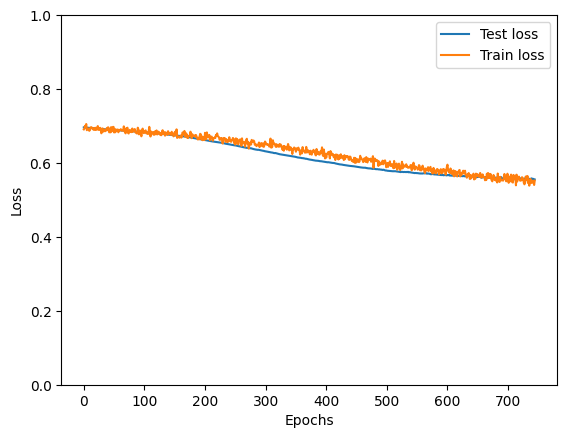

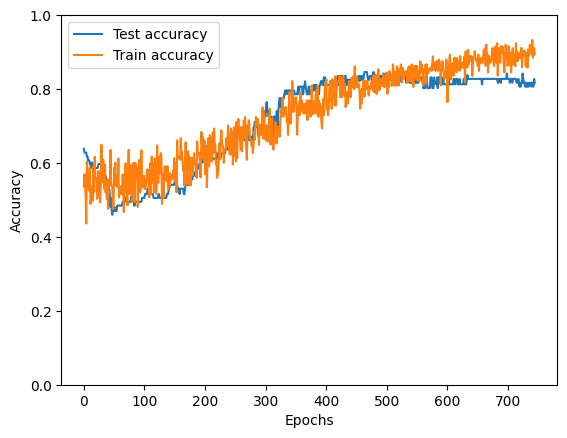

In [65]:
DEBUG = False
WEIGHTED = True

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

emb_dim = embeddings.shape[1]
audio_dim = audio_features.shape[1]
num_classes = len(df['dementia'].unique())

model = PittNet(emb_dim, audio_dim, num_classes, debug=DEBUG)
model = model.to(device)

# NOTE: Here I discover the trade off between using weighted and non-weighted data. Techically, passing weighted data is the correct way (due to class imbalance), however it might be benificial to
# work with non-weighted data. All depends on your point of view.

'''
Passing as weighted is more correct, cuz we have high skew towards dementia data. However, this lowers
recall on dementia, i.e. we get more false negatives, but almost no false positives.
It's a trade off:
Weighted - more correct, but we misdiagnose some dementia as control
Not-weighted - a litle less correct, but we misdiagnose dementia less (however we risk misdiagnosing control)
'''
if WEIGHTED:
    class_imbalance = Counter(y_train)
    weights = 1.0 / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
    weights = weights / weights.sum()  # Normalized weights 
    print(f'Weights: {weights}')
    loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
else:
    loss_fn = nn.CrossEntropyLoss()
    
print(f'Tokenizer model: {MODEL_TYPE} --- {"max pooling" if MAX_POOLING else "Average pooling"}')

optimizer = torch.optim.SGD([
                            {'params': model.audio_branch.parameters(), 'lr': 0.001},
                            {'params': model.embeddings_branch.parameters(), 'lr': 0.001},
                            {'params': model.demographics_branch.parameters(), 'lr': 0.001}
                            ], weight_decay=0.01)

debug_data = run_epochs(epochs=1000, patience=20, model=model, train_loader=train_loader, test_loader=test_loader, optimizer=optimizer, loss_fn=loss_fn, debug=DEBUG)




In [185]:
torch.save({
    'model_state': model.state_dict(),
    'text_dim': emb_dim,
    'audio_dim': audio_dim,
    'audio_scaler': train_dataset.audio_scaler,
    'age_scaler': train_dataset.age_scaler,
    'num_classes': num_classes,
    'class_names': ['Control', 'Dementia']
}, '/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/TEST_MODEL.pth')

# Cross validation

In [30]:
# NOTE: This snippet helps with choosing the best model by performing 10 fold crossvalidation.
# Basically, we run training and testing 10 times and take the best run. 

full_dataset = PittDataset(embeddings, audio_features, age, sex, labels)

n_splits = 10
sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=0.3)

fold_results = {
    'train_acc': [],
    'test_acc': [],
    'train_f1': [],
    'test_f1': [],
    'train_auc': [],
    'test_auc': [],
    'train_recall': [],
    'test_recall': [],
    'train_precision': [],
    'test_precision': [],
    'confusion_matrices': []
}

best_results = {
    'test_acc': 0.0,
    'test_f1': 0.0,
    'test_auc': 0.0,
    'test_recall': 0.0,
    'test_precision': 0.0,
}

for fold, (train_idx, test_idx) in enumerate(sss.split(embeddings, labels)):
    print(f"\n{'='*40}")
    print(f"Fold {fold + 1}/{n_splits}")
    print(f"{'='*40}")
    
    train_subset = Subset(full_dataset, train_idx)
    test_subset = Subset(full_dataset, test_idx)
    
    train_emb = embeddings[train_idx]
    train_audio = audio_features[train_idx]
    train_age = age[train_idx].reshape(-1, 1)
    train_sex = sex[train_idx].reshape(-1, 1)
    train_labels = labels[train_idx]
    
    test_emb = embeddings[test_idx]
    test_audio = audio_features[test_idx]
    test_age = age[test_idx].reshape(-1, 1)
    test_sex = sex[test_idx].reshape(-1, 1)
    test_labels = labels[test_idx]
    
    train_dataset = PittDataset(train_emb, train_audio, train_age, train_sex, train_labels)
    test_dataset = PittDataset(test_emb, test_audio, test_age, test_sex, test_labels, 
                             train_dataset.audio_scaler, train_dataset.age_scaler)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = PittNet(emb_dim, audio_dim, num_classes, debug=False)
    model = model.to(device)
    
    if WEIGHTED:
        class_imbalance = Counter(train_labels)
        weights = 1.0 / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
        weights = weights / weights.sum()  
        print(f'Weights: {weights}')
        loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
    else:
        loss_fn = nn.CrossEntropyLoss()
    print(f'Tokenizer model: {MODEL_TYPE} --- {"max pooling" if MAX_POOLING else "Average pooling"}')
    
    optimizer = torch.optim.SGD([
        {'params': model.audio_branch.parameters(), 'lr': 0.001},
        {'params': model.embeddings_branch.parameters(), 'lr': 0.001},
        {'params': model.demographics_branch.parameters(), 'lr': 0.001}
    ], weight_decay=0.01)
    
    final_metrics = run_epochs(epochs=1000, patience=30, model=model, train_loader=train_loader, 
                           test_loader=test_loader, optimizer=optimizer, 
                           loss_fn=loss_fn, debug=DEBUG, plots=False)
    
    fold_results['train_acc'].append(final_metrics['train_acc'])
    fold_results['test_acc'].append(final_metrics['test_acc'])
    fold_results['train_f1'].append(final_metrics['train_f1'])
    fold_results['test_f1'].append(final_metrics['test_f1'])
    fold_results['train_auc'].append(final_metrics['train_auc'])
    fold_results['test_auc'].append(final_metrics['test_auc'])
    fold_results['train_recall'].append(final_metrics['train_recall'])
    fold_results['test_recall'].append(final_metrics['test_recall'])
    fold_results['train_precision'].append(final_metrics['train_precision'])
    fold_results['test_precision'].append(final_metrics['test_precision'])
    fold_results['confusion_matrices'].append(final_metrics['test_confusion_matrix'])

    #if best_results['test_acc'] < final_metrics['test_acc'] and best_results['test_f1'] < final_metrics['test_f1'] and best_results['test_auc'] < final_metrics['test_auc'] and best_results['test_recall'] < final_metrics['test_recall'] and best_results['test_precision'] < final_metrics['test_precision']:
    if best_results['test_auc'] < final_metrics['test_auc'] and best_results['test_recall'] < final_metrics['test_recall']:
        best_results['test_acc'] = final_metrics['test_acc']
        best_results['test_f1'] = final_metrics['test_f1']
        best_results['test_auc'] = final_metrics['test_auc']
        best_results['test_recall'] = final_metrics['test_recall']
        best_results['test_precision'] = final_metrics['test_precision']
        torch.save({
            'model_state': model.state_dict(),
            'text_dim': emb_dim,
            'audio_dim': audio_dim,
            'audio_scaler': train_dataset.audio_scaler,
            'age_scaler': train_dataset.age_scaler,
            'num_classes': num_classes,
            'class_names': ['Control', 'Dementia']
        }, f"/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/ACC{int(best_results['test_acc']*100)}_F1Sc{int(best_results['test_f1']*100)}_AUC{int(best_results['test_auc']*100)}_REC{int(best_results['test_recall']*100)}_PRE{int(best_results['test_precision']*100)}.pth")

print(f"\n\n{n_splits}-fold Cross-Validation Results Summary:")
print("="*50)
for metric in fold_results:
    if metric != 'confusion_matrices':
        values = fold_results[metric]
        print(f"{metric}: {np.mean(values):.2f} ± {np.std(values):.2f}")

avg_confusion = np.mean(fold_results['confusion_matrices'], axis=0)
print("\nAverage Confusion Matrix:")
print(f"Confusion matrix cheatsheet: \n{np.array([['TN', 'FP'], ['FN', 'TP']])}")
print(f"Average confusion matrix: \n{avg_confusion}")


Fold 1/10
Weights: tensor([0.6601, 0.3399])
Tokenizer model: bge-base-en-v1.5 --- Average pooling
Epoch 0:999------------------------
Train loss: 0.76006 | Train accuracy: 0.48 | Train F1: 0.56 | Train AUC: 0.50 | Train Recall: 0.49 | Train Precision: 0.66
Test loss: 0.75767 | Test accuracy: 0.39  | Test F1: 0.46 | Test AUC: 0.39 | Test Recall: 0.40 | Test Precision: 0.56
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[35 34]
 [68 66]]
Test confusion matrix: 
[[11 18]
 [35 23]]

Epoch 10:999------------------------
Train loss: 0.76048 | Train accuracy: 0.49 | Train F1: 0.56 | Train AUC: 0.50 | Train Recall: 0.49 | Train Precision: 0.66
Test loss: 0.72631 | Test accuracy: 0.39  | Test F1: 0.46 | Test AUC: 0.39 | Test Recall: 0.40 | Test Precision: 0.56
Confusion matrix cheatsheet: 
[['TN' 'FP']
 ['FN' 'TP']]
Train confusion matrix: 
[[35 34]
 [69 65]]
Test confusion matrix: 
[[11 18]
 [35 23]]

Epoch 20:999------------------------
Train loss: 0.67545

# SHAP


### Whole model

In [ ]:
# NOTE: Here we perform SHAP to find out witch features are more important in classification
class WrappedPittNet(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model.eval()

    def forward(self, full_input):
        # full_input: [embeddings, audio, age, sex] concatenated
        emb_dim = self.model.embeddings_branch[0].in_features
        audio_dim = self.model.audio_branch[0].in_features

        embeddings = full_input[:, :emb_dim]
        audio = full_input[:, emb_dim:emb_dim+audio_dim]
        age = full_input[:, emb_dim+audio_dim].unsqueeze(1)
        sex = full_input[:, emb_dim+audio_dim+1].unsqueeze(1)

        logits, _ = self.model(embeddings, audio, age, sex)
        return logits


In [32]:
# get a small background sample for SHAP 
X_background = torch.cat([
    train_dataset[:250]['embeddings'],
    train_dataset[:250]['audio_features'],
    train_dataset[:250]['age'],
    train_dataset[:250]['sex'],
], dim=1)

X_test = torch.cat([
    test_dataset[:50]['embeddings'],
    test_dataset[:50]['audio_features'],
    test_dataset[:50]['age'],
    test_dataset[:50]['sex'],
], dim=1)


In [34]:

wrapped_model = WrappedPittNet(model).to(device)
X_background = X_background.to(device)
X_test = X_test.to(device)

explainer = shap.GradientExplainer(wrapped_model, X_background)
shap_values = explainer.shap_values(X_test)

In [35]:
X_test.cpu().numpy().shape

(50, 858)

In [36]:
shap_values[:,:,0].shape

(50, 858)

In [37]:
audio_feat_names = df.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).columns

/tmp/ipykernel_10063/86062082.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values[:,:,1], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])


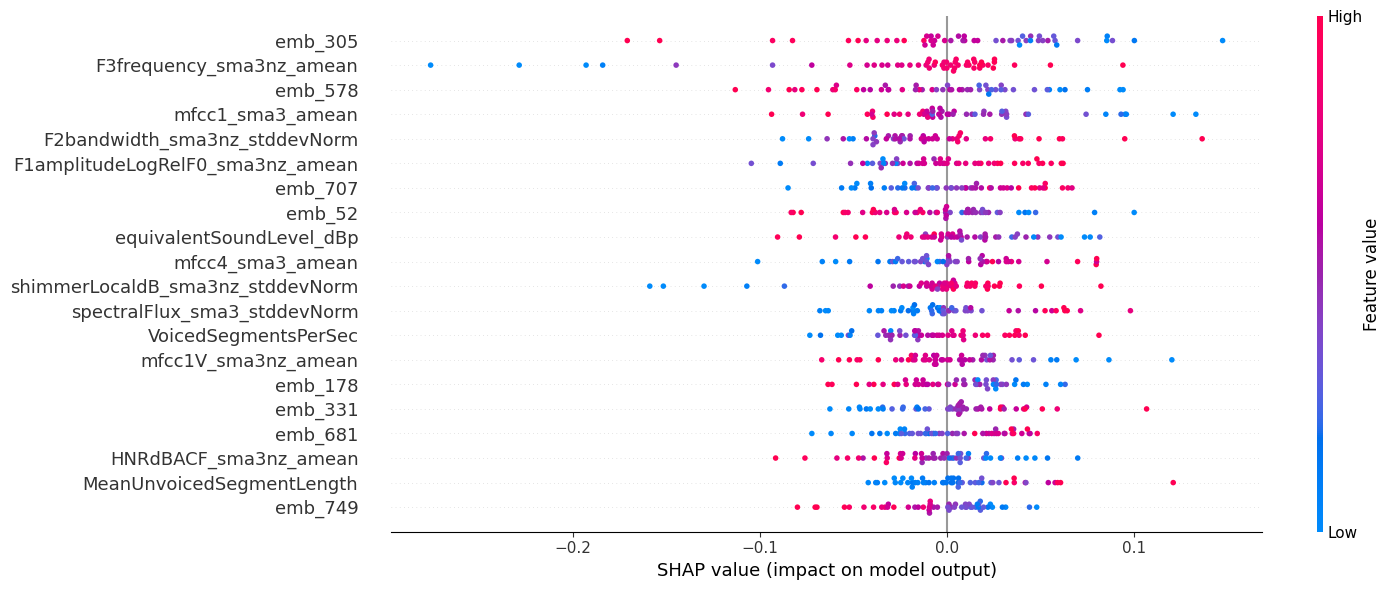

In [ ]:
# 1 for dementia
emb_dim = embeddings.shape[1]
audio_dim = audio_features.shape[1]

feature_names = (
    [f"emb_{i}" for i in range(emb_dim)] +
    [f"{audio_feat_names[i]}" for i in range(audio_dim)] +
    ["age", "sex"]
)
shap.summary_plot(shap_values[:,:,1], X_test.cpu().numpy(), feature_names=feature_names, plot_size=[15, 6])
# NOTE: This plot shows top 20 most important features. All of them show how exactly they contribute to prediction of dementia class;
# If the point is more to the right, then it contributes to classifying data as Dementia. The color of the point shows the value of the features.
# And the higher the feat in the list, the more important it was in classifying.
# As an example. MeanUnvoicedSegmentLength might appear in this list, the point for this value would get redder the further away they are to the right.
# This might be interpreted as such: People with dementia have more silent segments in their speech (i.e. trying hard to remember something, or struggling to form a sentance)
# NOTE 2: SHAP tends to show some emebeddings in this list. Unlike the audio features we can't really interpret what each specific embedding means (we don't know the difference between emb_001 and emb_768).
# However we can at least see how important these embeddings were in classifying (e.g. if the list contains more embeddings, then they were more important than audio features).
# Ideal SHAP would show us that embeddings and audio features are equaliy important, which shows that our model benefited from being multibranch

### Helper graph to understand audio feats
(FOR REFERENCE ONLY)

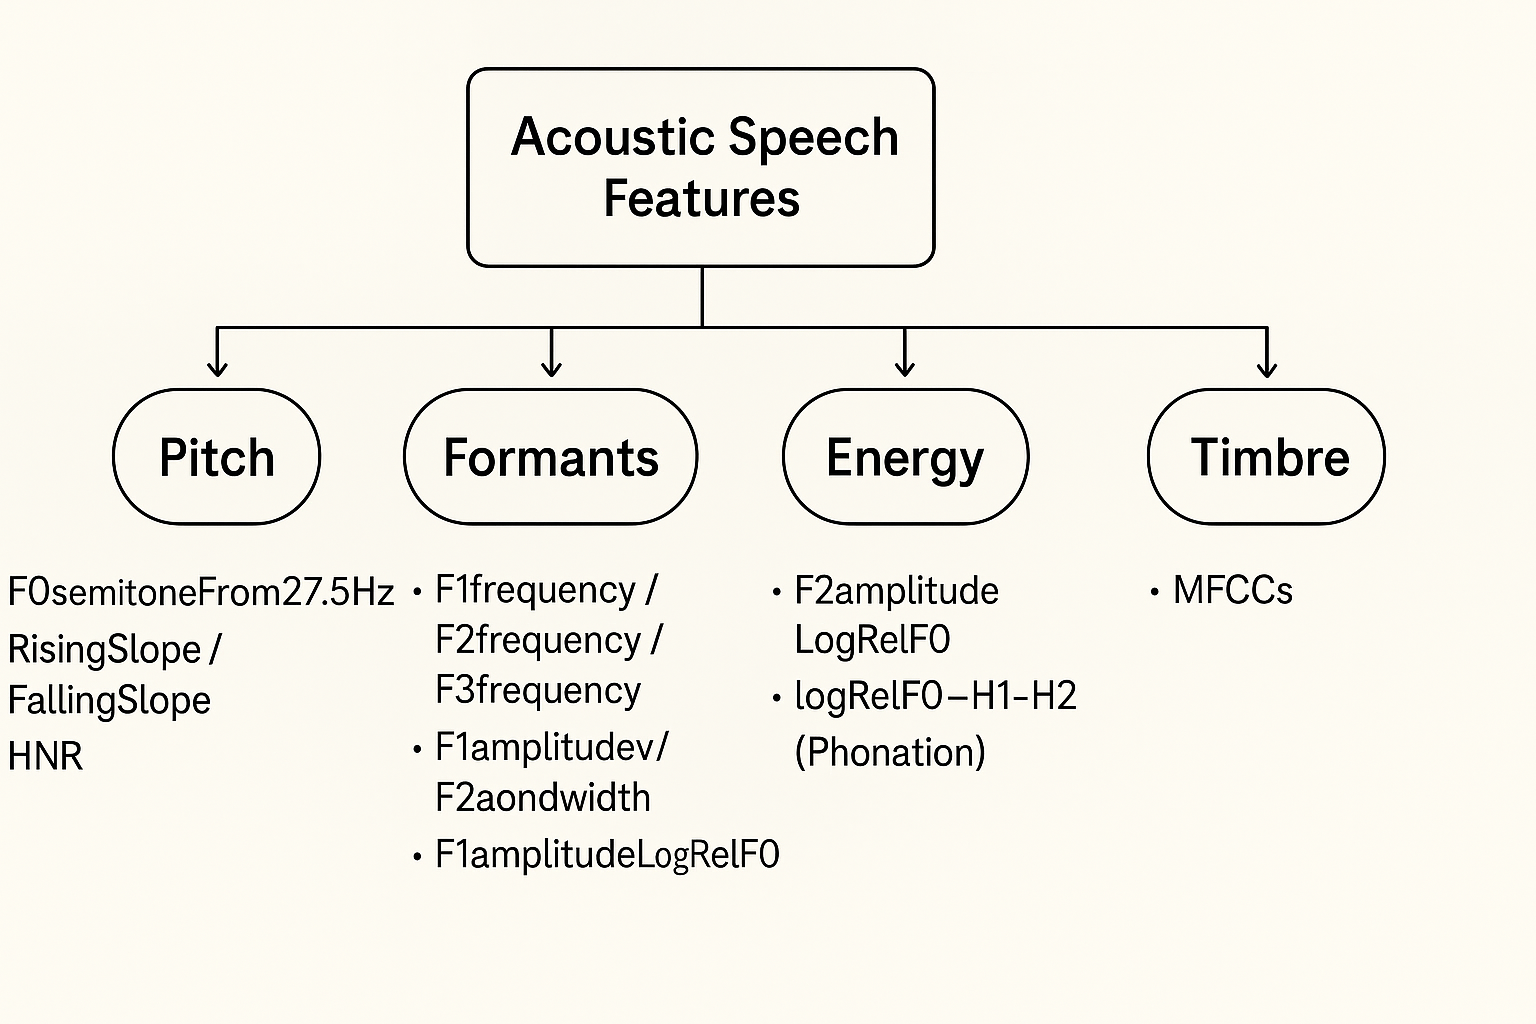

### Per branch

In [40]:
shap_values_branch = shap_values[:, :, 1]  # Use dementia class SHAP values

emb_end = 768
audio_end = emb_end + 88
demo_end = audio_end + 2  # total: 860

shap_emb = shap_values_branch[:, :emb_end]
shap_audio = shap_values_branch[:, emb_end:audio_end]
shap_demo = shap_values_branch[:, audio_end:demo_end]

X_emb = X_test[:, :emb_end]
X_audio = X_test[:, emb_end:audio_end]
X_demo = X_test[:, audio_end:demo_end]


/tmp/ipykernel_10063/1387088473.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_emb, X_emb.cpu().numpy(), feature_names=[f"emb_{i}" for i in range(emb_end)])


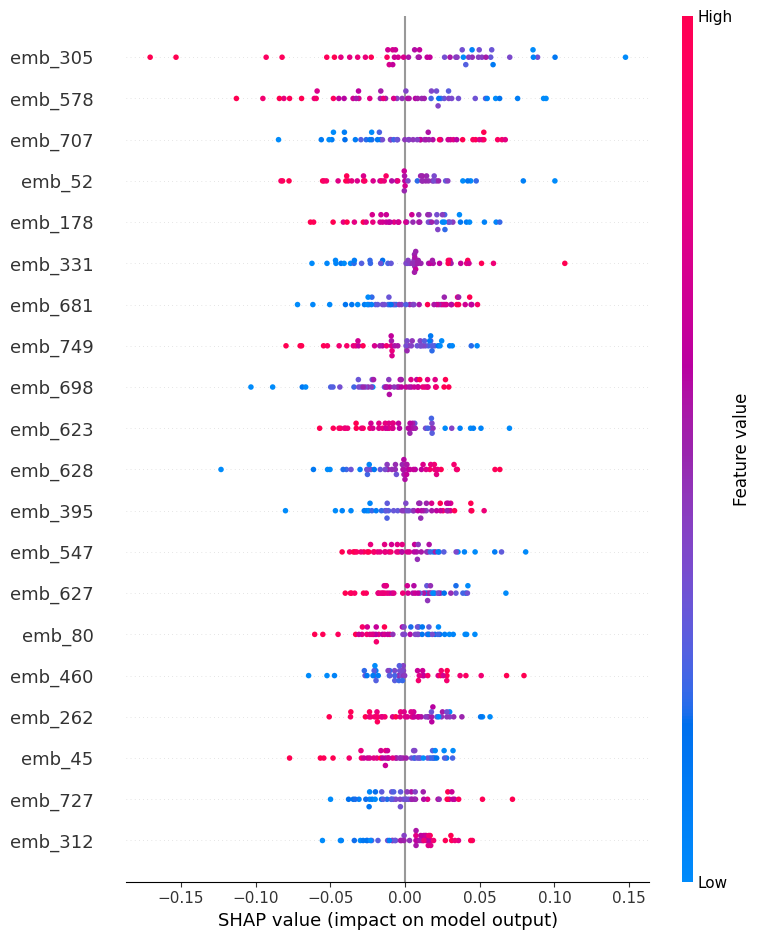

/tmp/ipykernel_10063/1387088473.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_audio, X_audio.cpu().numpy(), feature_names=[f"{audio_feat_names[i]}" for i in range(audio_dim)])


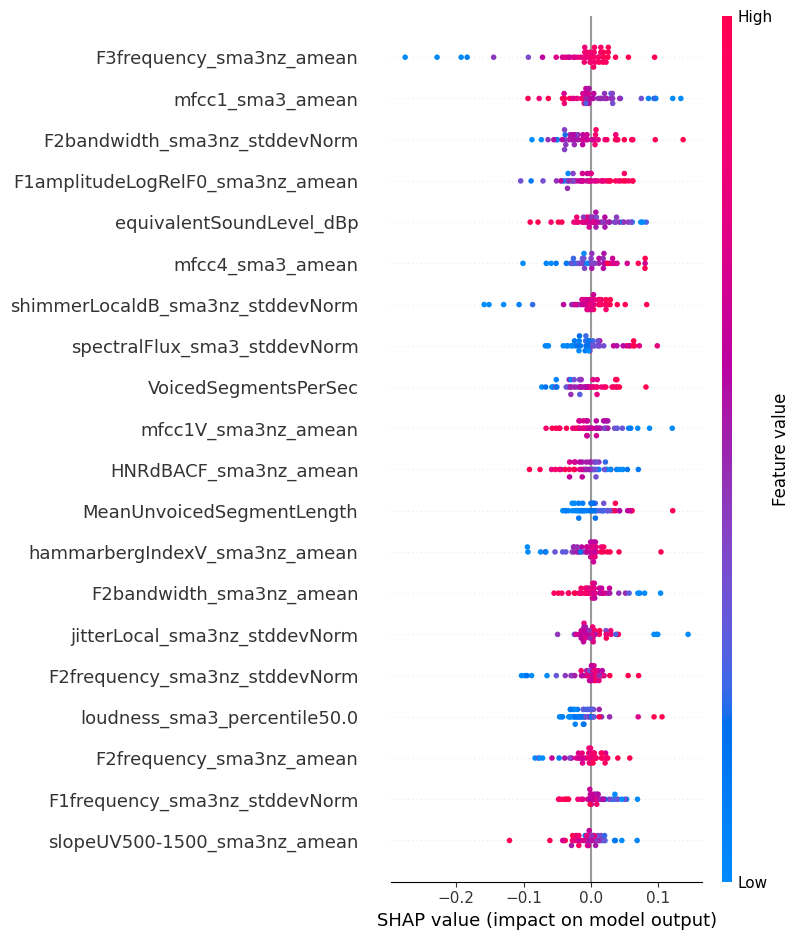

/tmp/ipykernel_10063/1387088473.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_demo, X_demo.cpu().numpy(), feature_names=["age", "sex"])


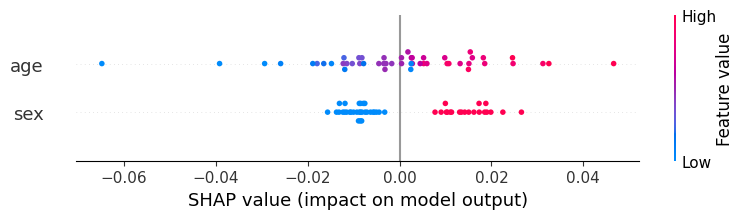

In [ ]:
shap.summary_plot(shap_emb, X_emb.cpu().numpy(), feature_names=[f"emb_{i}" for i in range(emb_end)])

shap.summary_plot(shap_audio, X_audio.cpu().numpy(), feature_names=[f"{audio_feat_names[i]}" for i in range(audio_dim)])

shap.summary_plot(shap_demo, X_demo.cpu().numpy(), feature_names=["age", "sex"])

# NOTE: This list shows how important were each value per branch. This helps us see some less important (and perhaps more obvious) things in different branches.
# Such as, age being more important in classification and higher age being assosiated with dementia.  

# Predictor (UNUSED)
Refrain from using this as is. The snippet shows some rudementary capability of the model to work with more or less similar data as a predictor. 


In [30]:
PATH_TO_MODEL = '/home/gabs/Documents/lab-NN/cognitive_impairments/data/models/ACC92_F1Sc94_AUC91_REC96_PRE93.pth'
def predict(PATH_TO_MODEL, emb, audio_features, age, sex, best_threshold = None, numerical_sex=False):
    checkpoint = torch.load(f=PATH_TO_MODEL, weights_only=False)
    age_scaler = checkpoint['age_scaler']
    audio_scaler = checkpoint['audio_scaler']
    
    emb = torch.tensor(emb, dtype=torch.float32)
    audio_features = torch.tensor(audio_scaler.transform(audio_features), dtype=torch.float32)
    age = torch.tensor(age_scaler.transform([[age]]), dtype=torch.float32)
    if numerical_sex:
        sex = torch.tensor([[sex]], dtype=torch.float32)
    else:
        sex = torch.tensor([[0 if sex == 'F' else 1]], dtype=torch.float32)

    class_names = checkpoint['class_names']

    predictor = PittNet(checkpoint['text_dim'], checkpoint['audio_dim'], checkpoint['num_classes'])
    predictor.load_state_dict(checkpoint['model_state'])
    predictor.eval()

    with torch.inference_mode():
        logits, _ = predictor(emb, audio_features, age, sex)
        if best_threshold == None:
            pred = F.softmax(logits, dim=1)
            return {
            'probability': float(pred.max()),
            'class': class_names[pred.argmax(dim=1)],
            }
        else:
            prob = F.softmax(logits, dim=1)[:, 1]
            pred = (prob > best_threshold).int()
            return {
            'Dementia probability': float(prob),
            'class': class_names[pred],
            }
        
    
    
    

In [ ]:
adresso = pd.read_pickle('/home/gabs/Documents/lab-NN/cognitive_impairments/data/DementiaBank/parsed_ADRESSO.pkl')
SIMPLE=True
sex_mapping = {'female': 0,
               'male': 1}
dementia_mapping = {'Control' : 0,
                    'PossibleAD' : 1,
                    'ProbableAD' : 1,
                    'Probable' : 1,
                    'Memory' : 2,
                    'Vascular' : 3,
                    'MCI' : 4,
                    'Other' : 5}

simple_dementia_mapping = {'Control' : 0,
                    'PossibleAD' : 1,
                    'ProbableAD' : 1,
                    'Probable' : 1,
                    'Memory' : 1,
                    'Vascular' : 1,
                    'MCI' : 1,
                    'Other' : 1}
adresso['sex'] = adresso['sex'].map(sex_mapping)

# I suppose we can keep simple mapping, cuz 'PossibleAD' and 'ProbableAD' are the most common (like 80% of the data)
if SIMPLE:
    adresso['dementia'] = adresso['dementia'].map(simple_dementia_mapping)
else:
    adresso['dementia'] = adresso['dementia'].map(dementia_mapping)

adresso = adresso.dropna()

In [32]:
adresso

,ID,age,sex,dementia,embeddings,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,...,slopeUV0-500_sma3nz_amean,slopeUV500-1500_sma3nz_amean,spectralFluxUV_sma3nz_amean,loudnessPeaksPerSec,VoicedSegmentsPerSec,MeanVoicedSegmentLengthSec,StddevVoicedSegmentLengthSec,MeanUnvoicedSegmentLength,StddevUnvoicedSegmentLength,equivalentSoundLevel_dBp
2,S136_cookie,79,1,1,"[[0.1622429, 0.06386103, 0.1419439, 0.01171796...",28.502918,0.092220,26.650621,28.916142,30.359406,...,0.004920,-0.006725,0.015559,1.277762,0.479977,0.498071,0.207255,3.254524,1.098766,-45.369053
3,S153_cookie,68,0,1,"[[-0.13641272, 0.025120603, 0.4695865, 0.02373...",33.893463,0.195800,30.401638,33.633354,36.526230,...,0.033429,-0.010736,0.087326,2.391511,1.363827,0.483929,0.312236,0.295405,0.324220,-25.333069
4,S143_cookie,60,0,1,"[[0.09699425, 0.13606128, 0.43917263, -0.20832...",30.126987,0.228446,25.005638,31.981270,33.638542,...,0.031159,-0.014041,0.038839,1.689608,1.531574,0.276114,0.340067,0.309781,0.287916,-26.715754
5,S118_cookie,77,0,1,"[[0.04755311, 0.2602899, 0.34900212, -0.059411...",30.478472,0.214575,26.783422,30.792650,33.569244,...,0.025279,-0.008670,0.079877,3.113026,2.623442,0.259634,0.180929,0.127193,0.134673,-28.666588
6,S110_cookie,73,0,1,"[[-0.20408152, 0.13424341, 0.1866002, 0.071866...",30.706264,0.130843,27.614120,31.195845,33.200001,...,0.025705,0.001578,0.022027,2.857491,1.092521,0.686296,0.158674,0.260018,0.183384,-32.373791
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,S055_cookie,70,1,0,"[[0.11069055, 0.025548514, 0.23647413, -0.0023...",24.407850,0.293110,19.424051,22.209169,28.354801,...,0.027329,-0.011826,0.491384,3.309641,2.750409,0.375573,0.256812,0.042723,0.019102,-20.087879
104,S015_cookie,70,0,0,"[[-0.07491915, -0.0036737747, 0.27406916, -0.0...",27.460943,0.247159,22.001646,26.952505,31.980383,...,0.009879,-0.004831,0.034917,4.049212,2.309686,0.190763,0.107259,0.207746,0.165789,-42.117378
105,S019_cookie,57,0,0,"[[-0.094108336, 0.24077725, 0.400946, 0.016361...",29.627216,0.259016,21.579857,31.489574,36.095100,...,0.041131,-0.009582,0.035128,2.410023,1.831259,0.380194,0.241024,0.229962,0.191916,-32.746468
106,S048_cookie,64,1,0,"[[-0.13421784, 0.27415794, 0.49581262, -0.0364...",21.962740,0.301942,17.423668,19.872877,25.061335,...,0.042658,-0.009217,0.100968,3.434928,1.872391,0.399952,0.219192,0.306400,0.374333,-28.437523


In [33]:
adresso_embeddings = np.stack(adresso['embeddings'].values)
adresso_audio_features = adresso.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values
adresso_age = adresso['age'].values
adresso_sex = adresso['sex'].values
adresso_labels = adresso['dementia'].values

if len(adresso_embeddings.shape) > 2:
    adresso_embeddings = np.squeeze(adresso_embeddings, axis=1)

In [34]:
p_model = PittNet(emb_dim, audio_dim, num_classes)
p_model.load_state_dict(torch.load(f=PATH_TO_MODEL, weights_only=False)['model_state'])

<All keys matched successfully>

In [35]:
adresso_set = PittDataset(adresso_embeddings, adresso_audio_features, adresso_age, adresso_sex, adresso_labels)
adresso_loader = DataLoader(adresso_set, batch_size=32, shuffle=False)

In [ ]:
p_model.eval()
p_model = model.to(device)
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        emb = batch['embeddings'].to(device)
        audio = batch['audio_features'].to(device)
        age = batch['age'].to(device)
        sex = batch['sex'].to(device)
        labels = batch['label'].to(device)
        
        logits, _ = p_model(emb, audio, age, sex)
        
        probs = torch.softmax(logits, dim=1)[:, 1]  # probability of class 1 (dementia)
        
        all_preds.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

y_true = np.concatenate(all_labels)
y_scores = np.concatenate(all_preds)

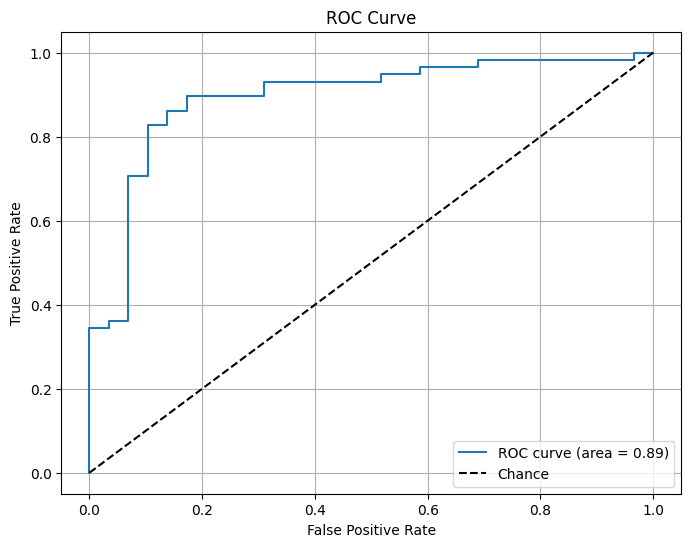

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = roc_auc_score(y_true, y_scores)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance') 
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid()
plt.show()


In [38]:
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]

print(f"Best Threshold by Youden's J: {best_threshold:.2f}")

Best Threshold by Youden's J: 0.76


In [40]:
#Resetting threshold for debugging
best_threshold = 0.5

In [ ]:
class_imbalance = Counter(adresso_labels)
weights = 1. / torch.tensor([class_imbalance[0], class_imbalance[1]], dtype=torch.float32)  
weights = weights / weights.sum()  
print(weights) 

loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))


with torch.inference_mode():
    p_model = p_model.to(device)

    p_model.eval()
    test_loss, test_acc = 0, 0

    all_test_preds = []
    all_test_labels = []
    
    for batch in adresso_loader:
        emb = batch['embeddings'].to(device)
        audio = batch['audio_features'].to(device)
        age = batch['age'].to(device)
        sex = batch['sex'].to(device)
        test_labels = batch['label'].to(device)
        test_logits, _ = p_model(emb, audio, age, sex)
        test_probs = F.softmax(test_logits, dim=1)[:, 1]
        loss = loss_fn(test_logits, test_labels)

        test_pred = (test_probs > best_threshold).int()

        test_loss += loss.item()
        test_acc += accuracy_score(test_labels.cpu(), test_pred.cpu())

        all_test_preds.extend(test_pred.cpu())
        all_test_labels.extend(test_labels.cpu())

    test_loss /= len(test_loader)
    test_acc /= len(test_loader)
    test_acc = accuracy_score(all_test_labels, all_test_preds)
    test_acc *= 100 # convert to %
    test_f1 = f1_score(all_test_labels, all_test_preds)
    test_auc = roc_auc_score(all_test_labels, all_test_preds)
    test_recall = recall_score(all_test_labels, all_test_preds)
    test_precision = precision_score(all_test_labels, all_test_preds)
    test_con_mat = confusion_matrix(all_test_labels, all_test_preds)
    test_report = classification_report(all_test_labels, all_test_preds)
    
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%  | Test F1: {test_f1:.2f} | Test AUC: {test_auc:.2f} | Test Recall: {test_recall:.2f} | Test Precision: {test_precision:.2f}")
    print(f"Confusion matrix cheatsheet: \n{np.array([['TP', 'FN'], ['FP', 'TN']])}")
    print(f"Test confusion matrix: \n{test_con_mat}\n")
    print(f'Test: \n{test_report}\n')
       
    print(all_test_preds)
    print(all_test_labels)

tensor([0.4906, 0.5094])
Test loss: 1.09646 | Test accuracy: 50.00%  | Test F1: 0.66 | Test AUC: 0.51 | Test Recall: 1.00 | Test Precision: 0.50
Confusion matrix cheatsheet: 
[['TP' 'FN']
 ['FP' 'TN']]
Test confusion matrix: 
[[ 1 53]
 [ 0 52]]

Test: 
              precision    recall  f1-score   support

           0       1.00      0.02      0.04        54
           1       0.50      1.00      0.66        52

    accuracy                           0.50       106
   macro avg       0.75      0.51      0.35       106
weighted avg       0.75      0.50      0.34       106


[tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(1, dtype=torch.int32)

In [202]:
for i in range(105):
    adresso_embeddings = np.stack(adresso['embeddings'].values)[i]
    adresso_audio_features = adresso.drop(columns=['ID', 'embeddings', 'dementia', 'age', 'sex']).values[i].reshape(1, -1)
    adresso_age = adresso['age'].values[i]
    adresso_sex = adresso['sex'].values[i]
    adresso_label = adresso['dementia'].values[i]

    if len(adresso_embeddings.shape) > 2:
        adresso_embeddings = np.squeeze(adresso_embeddings, axis=1)
    print('------------------')
    print(adresso_label)
    print(predict(PATH_TO_MODEL, adresso_embeddings, adresso_audio_features, adresso_age, adresso_sex, numerical_sex=True))

------------------
1
{'probability': 0.810393750667572, 'class': 'Dementia'}
------------------
1
{'probability': 0.8757587671279907, 'class': 'Dementia'}
------------------
1
{'probability': 0.8776484727859497, 'class': 'Dementia'}
------------------
1
{'probability': 0.9056530594825745, 'class': 'Dementia'}
------------------
1
{'probability': 0.8959349989891052, 'class': 'Dementia'}
------------------
1
{'probability': 0.8592215776443481, 'class': 'Dementia'}
------------------
1
{'probability': 0.5478663444519043, 'class': 'Control'}
------------------
1
{'probability': 0.7715389132499695, 'class': 'Dementia'}
------------------
1
{'probability': 0.5594080686569214, 'class': 'Control'}
------------------
1
{'probability': 0.9008183479309082, 'class': 'Dementia'}
------------------
1
{'probability': 0.8943338394165039, 'class': 'Dementia'}
------------------
1
{'probability': 0.8789064884185791, 'class': 'Dementia'}
------------------
1
{'probability': 0.8715561032295227, 'class': '

In [ ]:
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals,
)

def aggregate_features(participant_dir):
    features = []
    for utterance_file in os.listdir(participant_dir):
        utterance_path = os.path.join(participant_dir, utterance_file)
        feat = smile.process_file(utterance_path) 
        features.append(feat.squeeze()) 
    
    return pd.DataFrame(features).mean(axis=0).to_dict()  


tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
bert_model = AutoModel.from_pretrained('bert-base-uncased')
def get_embeddings(text):
    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=512)
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state.mean(dim=1).numpy()  

In [46]:
with open('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/transcript/control_transcript_test.txt', "r") as fin:
    transcript = fin.readlines()[0]
test_embeddings = get_embeddings(transcript)
test_audio_feats = aggregate_features('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/audio/test_control/')
test_df = pd.DataFrame([test_audio_feats])
test_audio_feats = test_df.values
predict(PATH_TO_MODEL, test_embeddings, test_audio_feats, 88, 'M', best_threshold=best_threshold)

{'Dementia probability': 0.7171819806098938, 'class': 'Dementia'}

In [47]:
with open('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/transcript/demented_transcript_test.txt', "r") as fin:
    transcript = fin.readlines()[0]
test_embeddings = get_embeddings(transcript)
test_audio_feats = aggregate_features('/home/gabs/Documents/lab-NN/cognitive_impairments/data/manual_recordings/audio/test_demented/')
test_df = pd.DataFrame([test_audio_feats])
test_audio_feats = test_df.values
predict(PATH_TO_MODEL, test_embeddings, test_audio_feats, 89, 'M', best_threshold=best_threshold)

{'Dementia probability': 0.8856819272041321, 'class': 'Dementia'}